In [3]:
import os
import ultralytics
from ultralytics import YOLO
import torch
import numpy as np
from skimage.measure import label, regionprops, regionprops_table
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics.yolo.utils.plotting import Annotator
torch.cuda.is_available()
ultralytics.checks()

def centroid(box):
    x1,y1,x2,y2=box
    cen_x=x1
    cen_y=y1
    return cen_x,cen_y
def AMM(mask,bbx):
    
    x1,y1,x2,y2=bbx
    width = x2 - x1
    height = y2 - y1
    
    major_axis=max(width,height)
    minor_axis=min(width,height)
    
    area=np.sum(mask)
    
    return major_axis,minor_axis,area,y1

Ultralytics YOLOv8.0.173  Python-3.9.17 torch-2.0.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3080 Laptop GPU, 8192MiB)
Setup complete  (20 CPUs, 31.7 GB RAM, 370.7/943.7 GB disk)


In [4]:
# !pip uninstall ultralytics

In [5]:
import tensorflow as tf
tf.test.is_gpu_available(
    cuda_only=False, min_cuda_compute_capability=None
)

True

In [4]:
os.path.exists('FV2/70/r2_c3_GOPR0072_JPG.rf.b0374dd5f5eae46a817eef9646b7befd.jpg')

False

In [6]:
def pred(img,model_path):
    #orig_img= plt.imread(img)
    orig_img=cv2.imread(img)
    shap=orig_img.shape
    #orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    model1 = YOLO(model_path)
    orig_img=cv2.resize(orig_img,(640,640))
    results = model1.predict(source=orig_img.copy(),conf=0.7)
    x_scale,y_scale=round(shap[1]/640,4),round(shap[0]/640,4)
    orig_img=cv2.resize(orig_img,None,fy=y_scale,fx=x_scale, interpolation=cv2.INTER_AREA)
    for result in results:                                         # iterate results
        boxes = result.boxes.cpu().numpy()                         # get boxes on cpu in numpy
        for i,box in enumerate(boxes):                                          # iterate boxes
            r = box.xyxy[0].astype(int) # get corner points as int  # print boxes
        
            r[0],r[1]=int(r[0]*x_scale),int(r[1]*y_scale)
            r[2],r[3]=int(r[2]*x_scale),int(r[3]*y_scale)
            cv2.putText(orig_img,f'bbx{i}',(int(r[0]),int(r[1])+100),fontFace = cv2.FONT_HERSHEY_SIMPLEX,fontScale = 0.6,color = (255, 255, 255),
                        thickness=2)
            cv2.rectangle(orig_img, r[:2], r[2:], (255, 255, 255), 2)
    #orig_img=cv2.resize(orig_img,None,fy=round(shap[0]/640,4),fx=round(shap[1]/640,4), interpolation=cv2.INTER_CUBIC)
    print(f'image shape {shap}, after {orig_img.shape}')
    plt.imshow(orig_img)
    plt.show()
    return results
    


0: 640x640 9 Plants, 58.6ms
Speed: 4.4ms preprocess, 58.6ms inference, 5.3ms postprocess per image at shape (1, 3, 640, 640)


image shape (345, 557, 3), after (345, 557, 3)


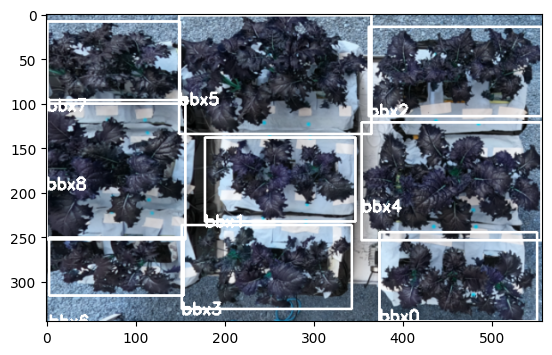

In [11]:
path=r"C:\Users\mzr0134\Box\new annotation tool\Test model\Picture1.png"

r=pred(path,'models/XL/r1/weights/best.pt')

In [7]:
####################################TO save Images###########################
############################################################################
# import shutil

# file_image='plant counting/models/s/pictures/70/'
# file='plant counting/models/s/s_r1_on_r2.csv.csv'
# img="work_df/raw data/round 2/images"
# # model_path0
# df=pd.read_csv(file)
# model1 = YOLO('models/s/r1/weights/best.pt')
# new_df=df[df.T_plant!=df.P_plant]
# for i in new_df.image:
#     to_path=os.path.join(file_image,i)
    
#     model1(source=os.path.join(img,i),save=True,project=file_image)

# file=[]
# rm=[]
# for root,dirs,files in os.walk(file_image):
#     for d in dirs:
#         for im in os.listdir(os.path.join(root,d)):
#             file.append((os.path.join(root,d,im),os.path.join(root,im)))
#             rm.append(os.path.join(root,d))
# for d,r in zip(file,rm):
#     shutil.move(d[0],d[1])
#     os.rmdir(r) 

In [12]:
def box_check(values):
    l={}
    for k,val in enumerate(values):
        ma,b=val
        r=box.xyxy[0].astype(int)
        are=(r[2]-r[0])*(r[3]-r[1])
        
        l['mask']=ma
        l["box"]=b
        l["a"]=are
    print(l)
    df=pd.DataFrame(l)
    df=df.sort_values(by=['are'],axis=1)
    return df

In [13]:
def check(results,imge):
    row=len(results[0])
    col=2
    j=0
    idx=0
    orig_img=cv2.imread(imge)
    orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    x_scale,y_scale=round(orig_img.shape[1]/640,4),round(orig_img.shape[0]/640,4)
    #orig_img=cv2.resize(orig_img,(640,640))
    print(orig_img.shape[:-1])
    plt.imshow(orig_img)
    regions=[]
    region2={}
    
    boxes1=results[0].boxes.cpu().numpy()
    fig,axes = plt.subplots(nrows = row, ncols = col, figsize=(50,50))
    for ax in axes.flatten():
        ax.axis('off')
    
    plt.figure(figsize=(50,50))
    for result in results:
    
        mask = result.masks.cpu().data.numpy()
#         mask=cv2.resize(mask,orig_img.shape[:-1])
        #masks = mask.masks.astype(bool)
        boxes=results[0].boxes.cpu().numpy()
        

        
        
        
        for i,v in enumerate(zip(mask,boxes)):
            m,box=v
            r = box.xyxy[0].astype(int)
            print(f'predicted mask shape {m.shape}')
            r[0],r[1]=int(r[0]*x_scale),int(r[1]*y_scale)
            r[2],r[3]=int(r[2]*x_scale),int(r[3]*y_scale)
            
#             print(m[0])
            m=cv2.resize(m,None,fy=round(y_scale,4),fx=round(x_scale,4), interpolation=cv2.INTER_CUBIC)
            print(f'resized mask shape {m.shape}')
            m=m.astype(bool)
            
            
            cen_x,cen_y=centroid(r)
            img=Image.fromarray(np.uint8(orig_img))
            cropped_image = img.crop(r)
               
        
            #new = np.zeros_like(orig_img, dtype=np.uint8)
            #new[m] = orig_img[m]
        
            #new=
        
            cropped_mask = Image.fromarray(np.uint8(m)).crop(r)
            arry=np.array(cropped_mask)
            region2[i]=(AMM(arry,r))
            df=pd.DataFrame(regionprops_table(arry.astype(int)*255,properties=('axis_major_length',
                                                 'axis_minor_length','area')))
            df['x']=r[0]
            df['y']=r[1]
            regions.append(df)
            n_black = cv2.countNonZero(arry)
            percent_of_bg=arry.shape[0]*arry.shape[1]-n_black
            #percent_of_bg=(arry.shape[0]*arry.shape[1]-n_black)/n_black *100
            
            axes[j,idx].imshow(cropped_image)
            axes[j,idx+1].imshow(cropped_mask)
            axes[j,idx+1].set_title((r[0],r[1]),fontweight ="bold")
            j+=1
    plt.show()
    return regions,region2


(2205, 2215)
predicted mask shape (640, 640)
resized mask shape (2205, 2215)
predicted mask shape (640, 640)
resized mask shape (2205, 2215)
predicted mask shape (640, 640)
resized mask shape (2205, 2215)
predicted mask shape (640, 640)
resized mask shape (2205, 2215)
predicted mask shape (640, 640)
resized mask shape (2205, 2215)
predicted mask shape (640, 640)
resized mask shape (2205, 2215)


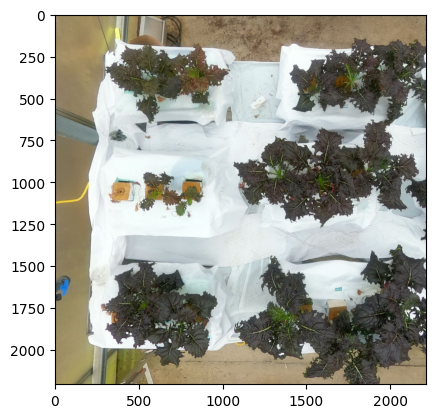

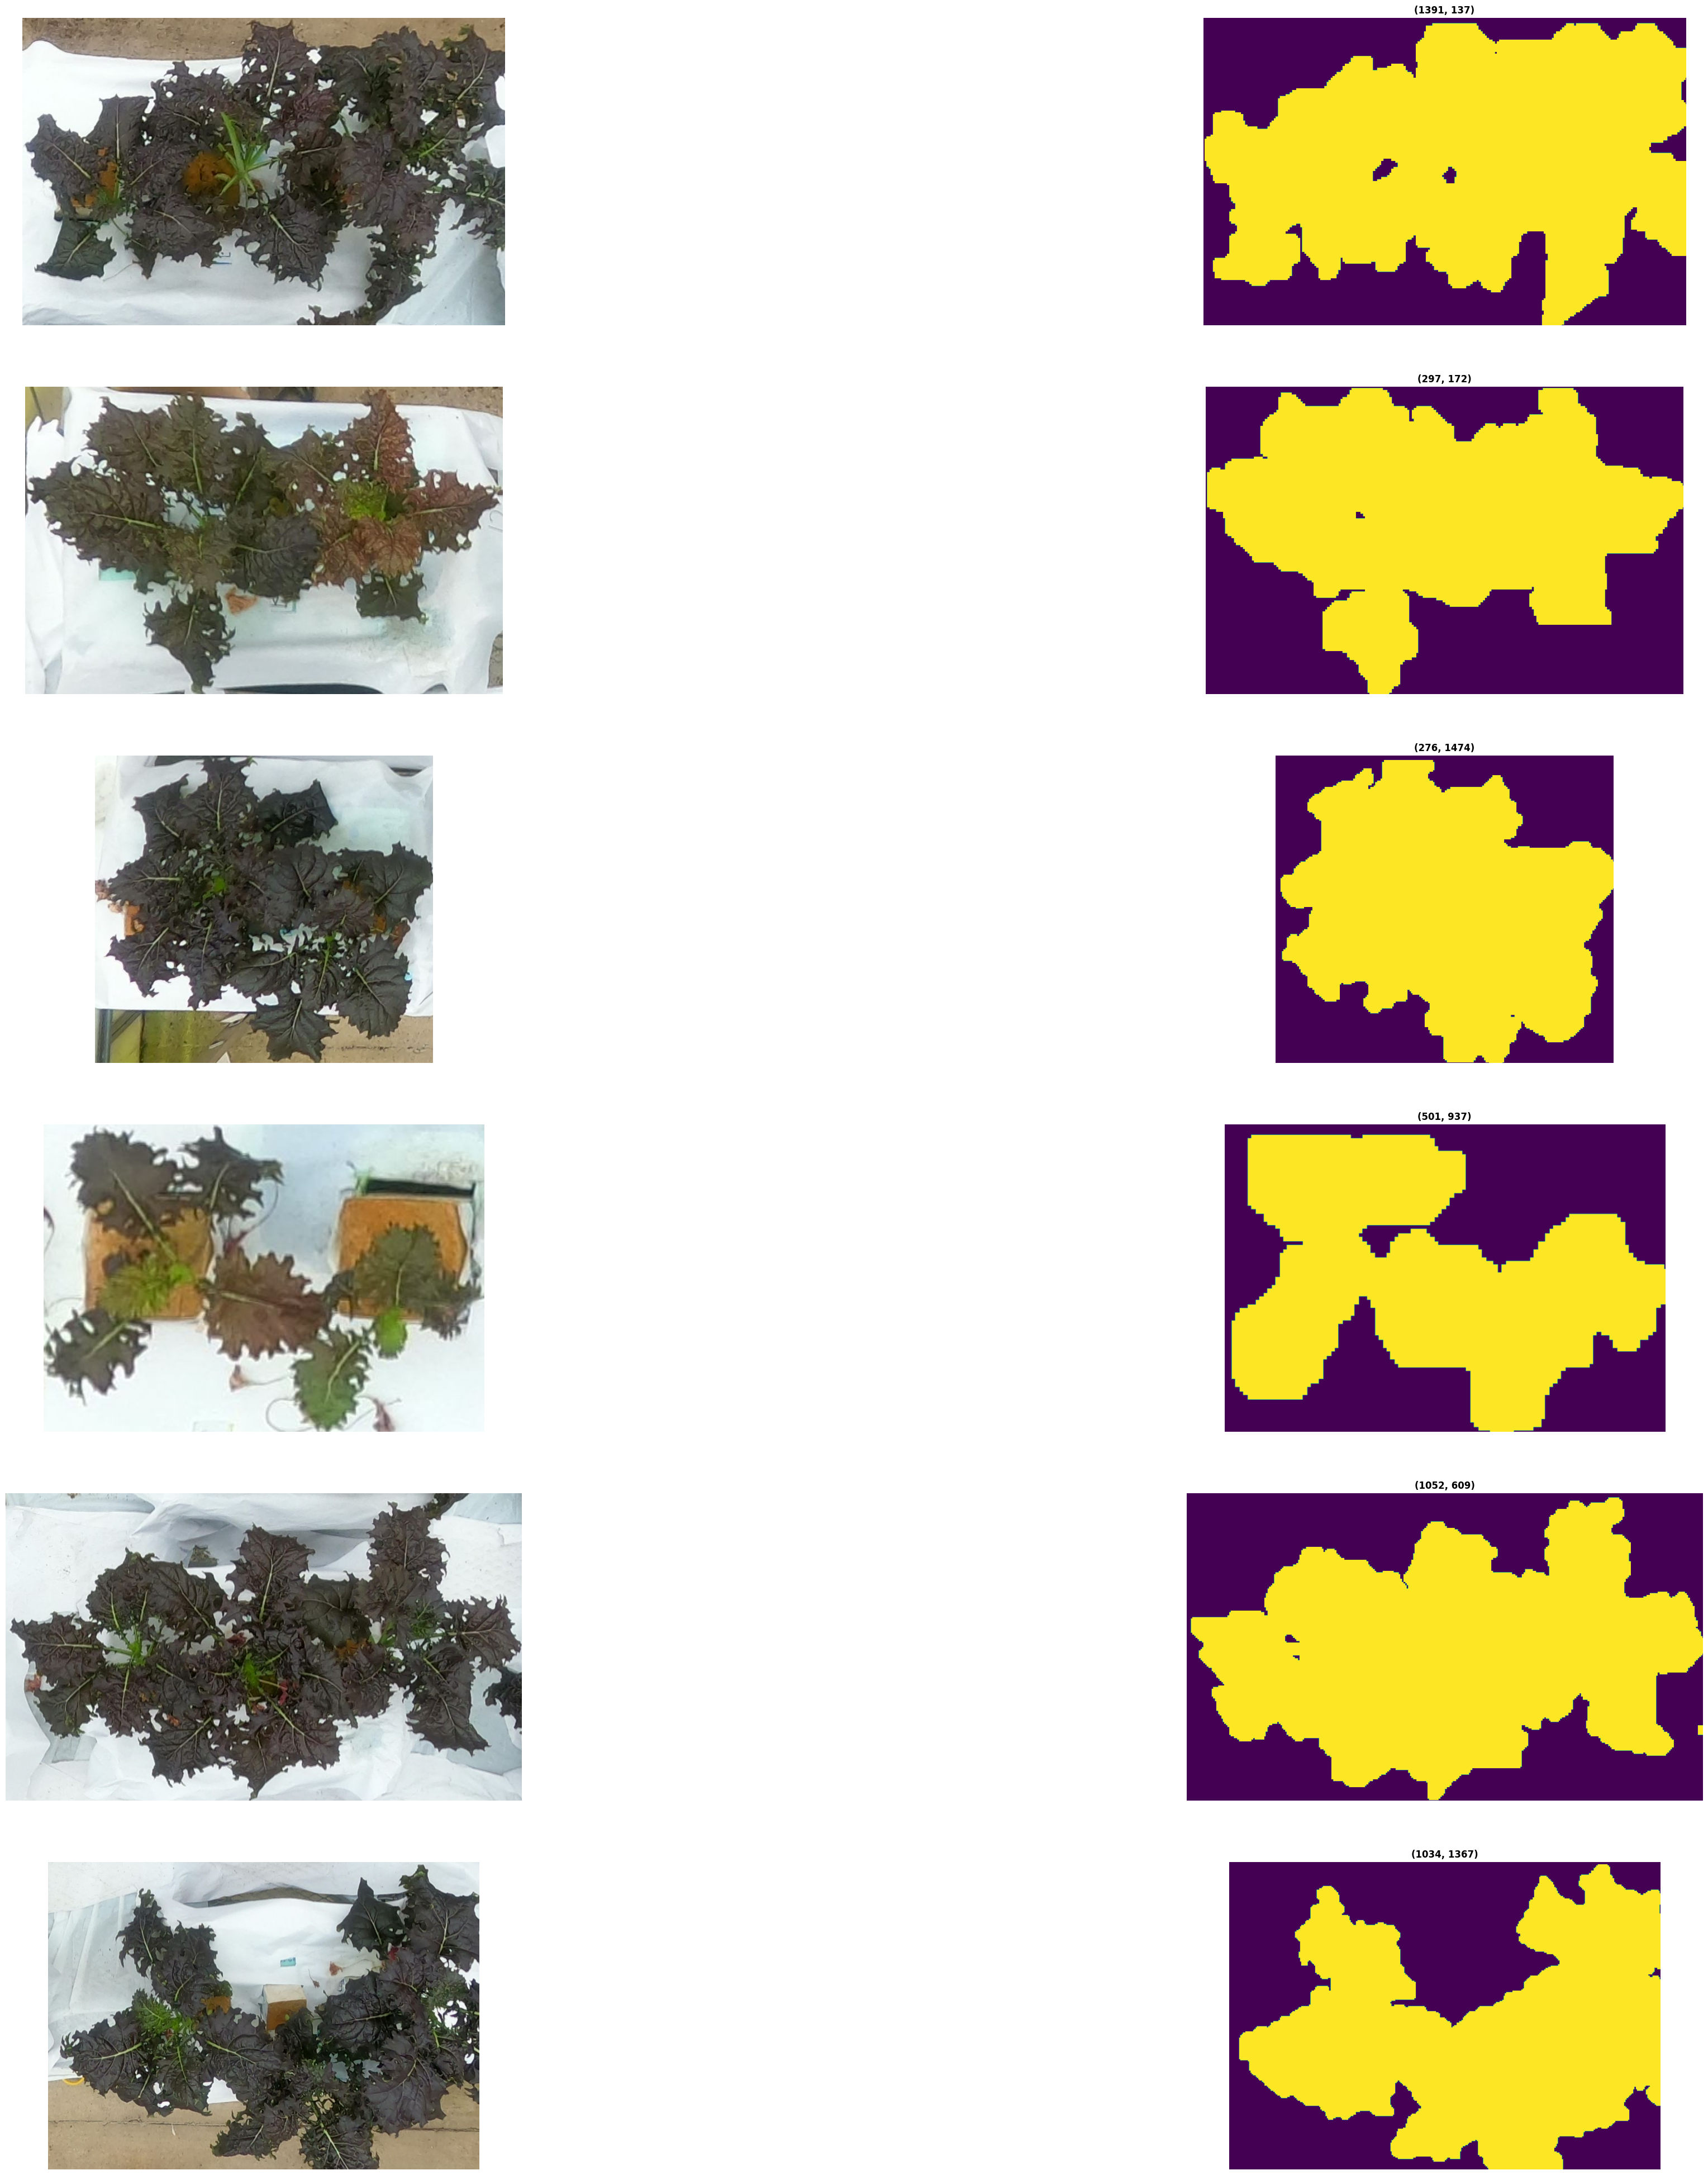

<Figure size 5000x5000 with 0 Axes>

In [45]:
re,re2=check(r,path)

In [22]:
# d1=pd.concat(re)
# d1.sort_values(by='y',ascending=True).iloc[0:6,:]


In [46]:
d1=pd.concat(re)

# d1.sort_values(by='y',ascending=True)
# d1.reset_index(inplace=True)
# d1.drop('index',axis=1,inplace=True)
d1

,axis_major_length,axis_minor_length,area,x,y
0,881.458059,457.405053,288698.0,1391,137
0,711.668249,398.086750,197364.0,297,172
0,700.010294,535.095621,279967.0,276,1474
0,407.340514,237.827720,56112.0,501,937
0,1097.969086,539.189118,428300.0,1052,609
0,1245.819014,750.531466,554430.0,1034,1367


In [30]:
#singlerootround1
cl3=[[1,1],[2,2],[3,3],[4,4],[5,1],[6,2],[7,3],[8,4],[9,1],[10,4],[11,2],[12,3]]

#singlerootround2
cl32=[[3,2],[2,4],[1,1],[4,3],[5,1],[6,2],[9,1],[8,2],[7,3],[10,4],[11,3],[12,4]]
def arrange2(frame,ci,img_name):
    """
    Arrange the image parameter according to the Plant ID and treatment.
    input: data frame, c1 =[plot ID, treatment], image name
    
    output: dataframe with proper ID and treatment assigned to it.
    
    """
    
    new_frame=frame.copy()
    new_frame['Plot']= 0
    new_frame['Treatment']= 0
    new_frame=new_frame.sort_values(['y'],ascending=[True])
    
    new_frame.reset_index(inplace=True)
    new_frame.drop('index',axis=1,inplace=True)
    i=0
    step=0
    idx=0
    df=[]
    while i< new_frame.shape[0]//3:
        
        new_frame1=new_frame[i+step-i:3+step].sort_values(['x'])#sort the data frame segment (low to high)
        new_frame1.reset_index(inplace=True)
        new_frame1.drop('index',axis=1,inplace=True)
        print(f'Vlaues would be{ci[i+step-i:3+step]}')
        for l,k in enumerate(ci[i+step-i:3+step]): # assign plot and treatment from low to high
            new_frame1.iloc[l,-2]=k[0]
            new_frame1.iloc[l,-1]=k[1]
    
        i+=1
        step+=3
        df.append(new_frame1)
    
    new_frame=pd.concat(df)
    new_frame['Image']=img_name
    new_frame.reset_index(inplace=True)
    return new_frame.drop(['index'],axis=1)
df=arrange2(d1,cl3,'name')
df

Vlaues would be[[1, 1], [2, 2], [3, 3]]
Vlaues would be[[4, 4], [5, 1], [6, 2]]
Vlaues would be[[7, 3], [8, 4], [9, 1]]
Vlaues would be[[10, 4], [11, 2], [12, 3]]


,axis_major_length,axis_minor_length,area,x,y,Plot,Treatment,Image
0,702.473819,463.981762,225467.0,617,217,1,1,name
1,487.736550,317.842289,105671.0,1134,517,2,2,name
2,703.771746,444.971235,220474.0,1368,691,3,3,name
3,275.990582,214.519928,30762.0,713,984,4,4,name
4,400.334559,317.280093,74192.0,1963,705,5,1,name
5,371.411157,350.934879,94067.0,2016,1057,6,2,name
6,326.988228,232.155358,53830.0,682,1292,7,3,name
7,430.817562,210.727412,53920.0,1016,1263,8,4,name
8,548.178425,395.105098,136302.0,1568,1314,9,1,name
9,373.688295,164.554762,43946.0,628,1632,10,4,name


In [31]:
##splitroot&sinle round1
c1=[[3,3],[6,2],[2,2],[5,1],[1,1],[4,4]]
c2=[[9,1],[12,3],[8,4],[11,2],[7,3],[10,4]]


#splitroot&sinle round2
c12=[[10,4],[7,3],[11,2],[8,4],[12,3],[9,1]]
c22=[[4,4,],[1,1],[5,1],[2,2],[6,2],[3,3]]


def arrange(frame,c,img_name):
    """
    Arrange the image parameter according to the Plant ID and treatment.
    input: data frame, c1 =[plot ID, treatment], image name
    
    output: dataframe with proper ID and treatment assigned to it.
    
    """
    
    new_frame=frame.copy()
    new_frame['Plot']= 0
    new_frame['Treatment']= 0
    new_frame=new_frame.sort_values(['y'],ascending=[True])
    new_frame.reset_index(inplace=True)
    i=0
    while i< new_frame.shape[0]//2:
        
        if new_frame.iloc[i+i,-4]>new_frame.iloc[i+i+1,-4]:
            print('first one bigger')
            print(c[i+i+1][0],c[i+i+1][1],c[i+i][0],c[i+i][1])
            new_frame.loc[i+i,'Plot']=c[i+i+1][0]
            new_frame.loc[i+i,'Treatment']= c[i+i+1][1]
            new_frame.loc[i+i+1,'Plot']=c[i+i][0]
            new_frame.loc[i+i+1,'Treatment']= c[i+i][1]
        else:
            #print('first one smaller')
            #print(c[i+i][0],c[i+i][1],c[i+i+1][0],c[i+i+1][1],f'i={i}')
            new_frame.loc[i+i,'Plot']=c[i+i][0]
            new_frame.loc[i+i,'Treatment']= c[i+i][1]
            new_frame.loc[i+i+1,'Plot']=c[i+i+1][0]
            new_frame.loc[i+i+1,'Treatment']= c[i+i+1][1]
            
    
        i+=1
    
    new_frame['Image']=img_name
    return new_frame
#     return new_frame.drop(['index','x','y'],axis=1)


df=arrange(d1,c12,'name')
df

first one bigger
7 3 10 4
first one bigger
8 4 11 2
first one bigger
9 1 12 3


,index,axis_major_length,axis_minor_length,area,x,y,Plot,Treatment,Image
0,0,870.695263,468.028202,293696.0,1387,124,7,3,name
1,0,722.446057,428.603190,217224.0,301,141,10,4,name
2,0,1120.071737,553.307624,456486.0,1052,623,8,4,name
3,0,420.246112,258.726495,63295.0,494,923,11,2,name
4,0,1280.853371,754.145310,596308.0,1024,1360,9,1,name
5,0,723.861506,557.153818,300958.0,252,1443,12,3,name


In [154]:
pd.DataFrame(re2).T

,0,1,2,3
0,198,129,8883,75
1,178,130,8003,406
2,242,119,10590,233
3,212,124,8944,77
4,202,81,9551,260
5,212,97,9047,404


(640, 640)
(640, 640)


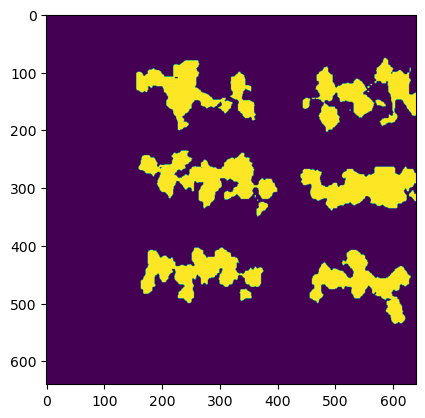

In [152]:
import matplotlib.pyplot as plt
masks=r[0].masks.masks
boxes=r[0].boxes.boxes
clas=boxes[:,5]
idx=torch.where(clas==0)
plant_mask=masks[idx]
plant_mask2= torch.any(plant_mask,dim=0).int() * 255
img_fi=plant_mask2.cpu().numpy()
print(img_fi.shape)
fig, ax = plt.subplots()
ax.imshow(img_fi)
print(img_fi.shape)

### Image information

In [79]:
path=r'C:\Users\mzr0134\Box\Split Root Experiment\Round_1\Images'
from PIL import Image
from PIL.ExifTags import TAGS

def get_capture_time(image_path):
    try:
        image = Image.open(image_path)
        exif_data = image._getexif()
        
        if exif_data is not None:
            for tag, value in exif_data.items():
                tag_name = TAGS.get(tag, tag)
                if tag_name == 'DateTimeOriginal':
                    return value
                
        return None
    except Exception as e:
        print(f"Error: {e}")
        return None

In [80]:
 get_capture_time(path+'\camera 2\GOPR0016.JPG')

'2022:10:27 10:27:35'

In [67]:
def timedata(path):
    info={}
    info2={}
    for root,dirs,files in os.walk(path):
        print(root)
        f=0
        while f <len(files)//2:
            print(f' f value is{f}, process {files[f+f]} & {files[f+f+1]}')
            info[root[-8:]+files[f+f]]=get_capture_time(os.path.join(root,files[f+f]))
            info2[root[-8:]+files[f+f+1]]=get_capture_time(os.path.join(root,files[f+f+1]))
        
            f+=1
    d1,d2=pd.DataFrame(info).T,pd.DataFrame(info2).T
    d1.columns,d2.columns=['Data','Time'],['Data','Time']
    return d1,d2
   
    

In [68]:
data1,data2=timedata(path)

C:\Users\mzr0134\Box\Split Root Experiment\Round_1\Images
C:\Users\mzr0134\Box\Split Root Experiment\Round_1\Images\camera 1
 f value is0, process GOPR0047.JPG & GOPR0048 (3).JPG
 f value is1, process GOPR0049.JPG & GOPR0050 (3).JPG
 f value is2, process GOPR0051.JPG & GOPR0052 (3).JPG
 f value is3, process GOPR0053.JPG & GOPR0054.JPG
 f value is4, process GOPR0055.JPG & GOPR0056 (2).JPG
 f value is5, process GOPR0057.JPG & GOPR0058 (2).JPG
 f value is6, process GOPR0059.JPG & GOPR0060 (2).JPG
 f value is7, process GOPR0062.JPG & GOPR0063.JPG
 f value is8, process GOPR0064.JPG & GOPR0065.JPG
 f value is9, process GOPR0066.JPG & GOPR0067.JPG
 f value is10, process GOPR0070.JPG & GOPR0071.JPG
 f value is11, process GOPR0072.JPG & GOPR0073.JPG
 f value is12, process GOPR0076.JPG & GOPR0078.JPG
 f value is13, process GOPR0079.JPG & GOPR0080.JPG
 f value is14, process GOPR0081.JPG & GOPR0082.JPG
 f value is15, process GOPR0083.JPG & GOPR0088.JPG
 f value is16, process GOPR0089.JPG & GOPR009

In [72]:
data1.head()

,Data,Time
camera 1GOPR0047.JPG,2022:10:24,11:54:22
camera 1GOPR0049.JPG,2022:10:25,09:21:53
camera 1GOPR0051.JPG,2022:10:26,09:45:36
camera 1GOPR0053.JPG,2022:10:27,10:23:54
camera 1GOPR0055.JPG,2022:10:28,10:25:28


In [73]:
data2.head()

,Data,Time
camera 1GOPR0048 (3).JPG,2022:10:24,11:54:26
camera 1GOPR0050 (3).JPG,2022:10:25,09:21:57
camera 1GOPR0052 (3).JPG,2022:10:26,09:45:40
camera 1GOPR0054.JPG,2022:10:27,10:24:00
camera 1GOPR0056 (2).JPG,2022:10:28,10:25:31


In [74]:
data1.tail()

,Data,Time
camera 3GOPR0055.JPG,2022:11:08,09:03:03
camera 3GOPR0057.JPG,2022:11:09,10:43:57
camera 3GOPR0059.JPG,2022:11:15,10:42:01
camera 3GOPR0061.JPG,2022:11:16,10:53:40
camera 3GOPR0063.JPG,2022:11:17,12:30:05


In [75]:
data2.tail()

,Data,Time
camera 3GOPR0056.JPG,2022:11:08,09:03:08
camera 3GOPR0058.JPG,2022:11:09,10:44:01
camera 3GOPR0060.JPG,2022:11:15,10:42:06
camera 3GOPR0062.JPG,2022:11:16,10:53:55
camera 3GOPR0064.JPG,2022:11:17,12:30:09



WARNING  'Masks.masks' is deprecated. Use 'Masks.data' instead.
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.
0: 608x640 7 Plants, 63.0ms
Speed: 3.0ms preprocess, 63.0ms inference, 2.0ms postprocess per image at shape (1, 3, 608, 640)
Results saved to runs\segment\predict30


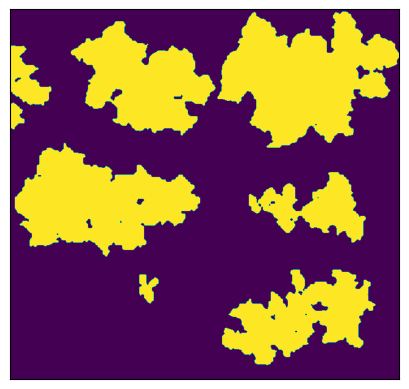

In [39]:
import cv2
from ultralytics import YOLO
import numpy as np
import torch


img= cv2.imread(r"C:\Users\mzr0134\Box\new annotation tool\Test model\work_df\raw data\round22(renamed)\r2_c2_GOPR0349.JPG")
model = YOLO("models/XL/r2/weights/best.pt")
results = model.predict(source=img.copy(), save=True, save_txt=False, stream=True)
for result in results:
    # get array results
    masks = result.masks.masks
    boxes = result.boxes.boxes
    # extract classes
    clss = boxes[:, 5]
    # get indices of results where class is 0 (people in COCO)
    people_indices = torch.where(clss == 0)
    # use these indices to extract the relevant masks
    people_masks = masks[people_indices]
    # scale for visualizing results
    people_mask = torch.any(people_masks, dim=0).int() * 255
    # save to file
    plt.imshow(people_mask.cpu().numpy())
    plt.xticks([])
    plt.yticks([])


0: 640x640 6 Plants, 39.1ms
Speed: 2.0ms preprocess, 39.1ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)


AttributeError: 'numpy.ndarray' object has no attribute 'save'

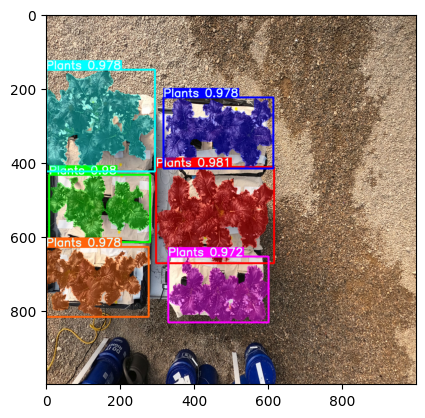

In [18]:
##Add color

colors = [
    (255, 0, 0),        # Red
    (0, 255, 0),        # Green
    (0, 0, 255),        # Blue
    (255, 100, 12),      # Yellow
    (0, 255, 255),      # Cyan
    (255, 0, 255),      # Magenta
    (255, 255, 255),    # White
    (0, 0, 0),          # Black
    (255, 165, 0),      # Orange
    (128, 0, 128),      # Purple
    (255, 192, 203),    # Pink
    (0, 128, 128)       # Teal
]
class_names=['Plants']

from ultralytics import YOLO
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def overlay(image, mask, color, alpha, resize=None):
    colored_mask = np.expand_dims(mask, 0).repeat(3, axis=0)
    colored_mask = np.moveaxis(colored_mask, 0, -1)
    masked = np.ma.MaskedArray(image, mask=colored_mask, fill_value=color)
    image_overlay = masked.filled()
    if resize is not None:
        image = cv2.resize(image.transpose(1, 2, 0), resize)
        image_overlay = cv2.resize(image_overlay.transpose(1, 2, 0), resize)

    image_combined = cv2.addWeighted(image, 1 - alpha, image_overlay, alpha, 0)

    return image_combined
           

def plot_one_box(x, img, color=None, label=None, line_thickness=3):
    # Plots one bounding box on image img
    tl = line_thickness or round(0.002 * (img.shape[0] + img.shape[1]) / 2) + 1  # line/font thickness
    color = color or [random.randint(0, 255) for _ in range(3)]
    c1, c2 = (int(x[0]), int(x[1])), (int(x[2]), int(x[3]))
    cv2.rectangle(img, c1, c2, color, thickness=tl, lineType=cv2.LINE_AA)
    if label:
        tf = max(tl - 1, 1)  # font thickness
        t_size = cv2.getTextSize(label, 0, fontScale=tl / 3, thickness=tf)[0]
        c2 = c1[0] + t_size[0], c1[1] - t_size[1] - 3
        cv2.rectangle(img, c1, c2, color, -1, cv2.LINE_AA)  # filled
        cv2.putText(img, label, (c1[0], c1[1] - 2), 0, tl / 3, [225, 255, 255], thickness=tf, lineType=cv2.LINE_AA)


c=0
# Load a model
model = YOLO(r"models\XL\r1\weights\best.pt")
img=cv2.imread('r1_c2_GOPR0030.jpg')
img=cv2.resize(img,(1000,1000))
h, w, _ = img.shape
#colors = [[random.randint(0, 255) for _ in range(3)] for _ in range(12)]
results = model.predict(img, stream=True,conf=0.7)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs
        masks = masks.data.cpu()

        for seg, box in zip(masks.data.cpu().numpy(), boxes):
           
            seg = cv2.resize(seg,(1000,1000))

            img = overlay(img, seg, colors[c], 0.4)
            xmin = int(box.data[0][0])
            ymin = int(box.data[0][1])
            xmax = int(box.data[0][2])
           
            ymax = int(box.data[0][3])
            if c>10:
                c=5
            plot_one_box([xmin, ymin, xmax, ymax], img, colors[c], f'{class_names[int(box.cls)]} {float(box.conf):.3}')
            c+=1
plt.imshow(img)
img.save("test.jpg")
c=0